# Лабораторна робота №3

Застосуйте статистичний тест до зібраних даних  

# Варіанти (1-8):  
На даних про втрати російських військ (можна взяти на сайті "Української Правди" або інших газет) перевірте гіпотези.
1. Припускаючи нормальні розподіли, перевірити гіпотезу про те, що середні втрати на день "ббм" збігається із втратами "автотехніка ппм". В статистиці дано суму. Розмір вибірки - кількість дні війни. Вважати, що $\sigma^2_1=sigma^2_2=100$
2. Припускаючи нормальний розподіл, перевірити гіпотезу про те, що середні втрати на день ворожого особового складу дорівнюють 500. Вважайте що $\sigma^2=250$. Розмір вибірки - кількість дні війни.
3. Припускаючи нормальні розподіли, перевірити гіпотезу про те, що середні втрати на день "ббм" збігається із втратами "танків" (домноженими на 2). В статистиці дано суму. Розмір вибірки - кількість дні війни. Вважати, що $\sigma_1^2=100$,  $\sigma_2^2=50$
4. За допомогою тесту хі-квадрат, перевірити гіпотезу про те, що втрати ворожих: гелікоптерів, літаків та засобів ппо - розподілені рівномірно

##### Для наступних варіантів формулювання лабораторних інше. 
Підкиньте деформовану (або несиметричну, або з дефектами, будь-яку) монетку 20 разів та запишіть рузультати випробувань 

5. Побудуйте довірчий інтервал рівня 95% для ймовірності випадання аверсу  
6. Побудуйте тест відношення вірогідності для $H_0:p=0.5$ проти $H_1:p=0.6$. Перевірте гіпотезу на вашій вибірці
7. Побудуйте двосторонній тест для розподілу бернулі $H_0:p=0.5$ проти $H_1:p\neq 0.5$. Перевірте гіпотезу на вашій вибірці
8. За допомогою тесту хі-квадрат, перевірте гіпотезу про те, що монетка є "чесною"

# Варіант 1. Середні втрати на день: ББМ і автомобільна техніка

**Дані** (Генштаб ЗСУ, станом на 26.10.2026, як публікують "Українська правда", "Главком"):

| | сума втрат |
|---|---|
| бойові броньовані машини (ББМ) | 25 609 |
| автомобільна техніка та автоцистерни (з ПММ) | 167 240 |
| день війни | 1706 |

Розмір вибірки $n = 1706$ (кількість днів війни, 24.02.2022 – 26.10.2026).

**Модель:**
- $\xi_1, ..., \xi_n \sim N(\mu_1, \sigma_1^2)$ — втрати ББМ за день
- $\eta_1, ..., \eta_n \sim N(\mu_2, \sigma_2^2)$ — втрати автотехніки за день
- $\sigma_1^2 = \sigma_2^2 = 100$ (відомі)

**Зауваження 1.** У статистиці дана тільки сума $\sum \xi_i$, а не втрати за кожен день окремо. Але для тесту потрібне лише середнє, а його можна знайти з суми:
$$\hat{\mu}_{1,n} = \frac{1}{n}\sum_{i=1}^n \xi_i, \quad \hat{\mu}_{2,n} = \frac{1}{n}\sum_{i=1}^n \eta_i$$

**Зауваження 2.** Вважаємо вибірки $\xi$ і $\eta$ незалежними (умова варіанта не дає коваріацію між ними).

## Стат критерій про рівність середніх, при відомих дисперсіях

Гіпотеза:
$H_0$: $\mu_1=\mu_2$
$H_1$: $\mu_1\neq \mu_2$

На семінарі для однієї вибірки: $\hat{\mu}_n \sim N\left(\mu, \frac{\sigma^2}{n}\right)$, тому при $H_0$: $\sqrt{n}\frac{(\hat{\mu}_n-\mu_0)}{\sqrt{\sigma^2}} \sim N(0, 1)$.

Для двох незалежних вибірок:
$$\hat{\mu}_{1,n} \sim N\left(\mu_1, \frac{\sigma_1^2}{n}\right), \quad \hat{\mu}_{2,n} \sim N\left(\mu_2, \frac{\sigma_2^2}{n}\right)$$

Різниця незалежних нормальних величин — нормальна, середні віднімаються, дисперсії додаються:
$$\hat{\mu}_{1,n} - \hat{\mu}_{2,n} \sim N\left(\mu_1 - \mu_2, \frac{\sigma_1^2 + \sigma_2^2}{n}\right)$$

При $H_0$ ($\mu_1 = \mu_2$):
$$\sqrt{n}\frac{(\hat{\mu}_{1,n}-\hat{\mu}_{2,n})}{\sqrt{\sigma_1^2+\sigma_2^2}} \sim N(0, 1)$$

Тест:

$\zeta_n=|\sqrt{n}\frac{(\hat{\mu}_{1,n}-\hat{\mu}_{2,n})}{\sqrt{\sigma_1^2+\sigma_2^2}}|$; $(Q^{N(0, 1)}(1 - a/2), \infty)$

Якщо $\zeta_n$ потрапляє в критичну область — приймаємо $H_1$, інакше $H_0$.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import norm
from tqdm import tqdm

np.random.seed(42)

# Перевірка гіпотези на даних

In [2]:
n = 1706

sum_bbm = 25609    # ББМ
sum_auto = 167240  # автомобільна техніка та автоцистерни

sigma1 = 100 ** 0.5
sigma2 = 100 ** 0.5

In [3]:
x_mean = sum_bbm / n
y_mean = sum_auto / n

x_mean, y_mean

(15.01113716295428, 98.03048065650644)

In [4]:
# test

def stat(x_mean, y_mean, n):
    return np.abs(n ** 0.5 * (x_mean - y_mean) / (sigma1 ** 2 + sigma2 ** 2) ** 0.5)

In [5]:
a = 0.05
kappa = norm(0, 1).ppf(1 - a / 2)

In [6]:
print(stat(x_mean, y_mean, n), kappa)
print("Приймаємо гіпотезу Н{}".format(int(stat(x_mean, y_mean, n) > kappa)))

242.46765390805515 1.959963984540054
Приймаємо гіпотезу Н1


**Розрахунки вручну:**

$\hat{\mu}_{1,n} = \frac{25609}{1706} = 15.011$

$\hat{\mu}_{2,n} = \frac{167240}{1706} = 98.030$

$\hat{\mu}_{1,n} - \hat{\mu}_{2,n} = 15.011 - 98.030 = -83.019$

$\sqrt{n} = \sqrt{1706} = 41.304, \quad \sqrt{\sigma_1^2 + \sigma_2^2} = \sqrt{100 + 100} = \sqrt{200} = 14.142$

$\zeta_n = \left|41.304 \cdot \frac{-83.019}{14.142}\right| = |41.304 \cdot (-5.870)| = 242.47$

$Q^{N(0, 1)}(1 - 0.05/2) = Q^{N(0, 1)}(0.975) = 1.96$

$242.47 > 1.96$, тобто $\zeta_n \in (1.96, \infty)$ — критична область $\Rightarrow$ **приймаємо $H_1$**.

# Ймовірність похибки першого роду

Похибка першого роду — відхилити $H_0$, коли вона правильна. Тест будувався так, щоб $P(\text{похибка I роду}) = a = 0.05$.

Перевіримо моделюванням: генеруємо дві вибірки при $H_0$ ($\mu_1 = \mu_2 = \mu_0$) $H$ разів і рахуємо частку, коли тест прийняв $H_1$.

In [7]:
# Under H0
H = 10000

mu0 = 0

first_error_rate = []

for n_ in tqdm(range(200, 5001, 200)):
    hyps = []
    for _ in (range(H)):
        x = np.random.normal(mu0, sigma1, size=n_)
        y = np.random.normal(mu0, sigma2, size=n_)
        hyps.append(int(stat(x.mean(), y.mean(), n_) > kappa))

    hyps = np.array(hyps)
    first_error_rate.append((hyps == 1).mean())

100%|██████████| 25/25 [00:25<00:00,  1.03s/it]


In [8]:
(hyps == 1).mean(), a

(np.float64(0.0484), 0.05)

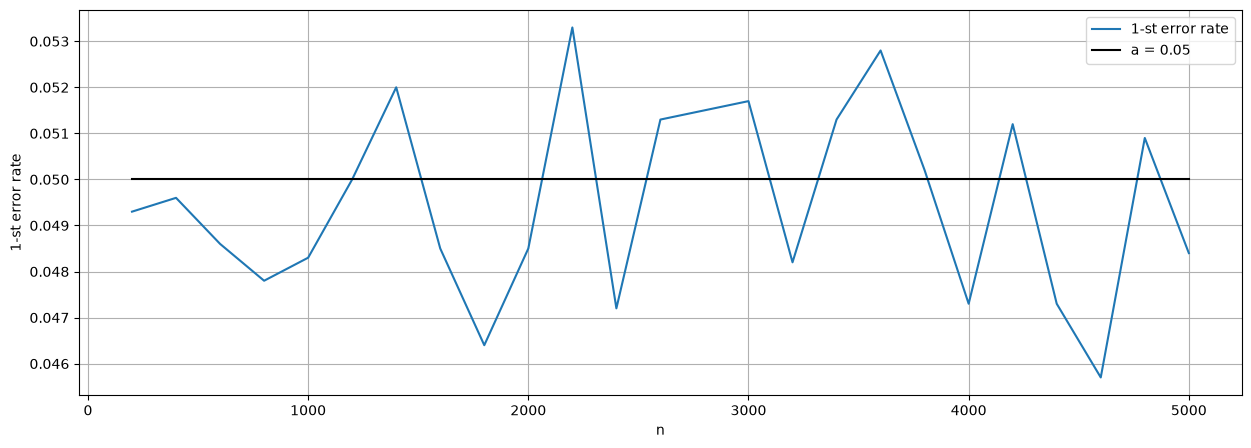

In [9]:
plt.figure(figsize=(15, 5))
plt.plot(range(200, 5001, 200), first_error_rate, label='1-st error rate')
plt.plot([200, 5000], [a, a], color='black', label='a = 0.05')
plt.xlabel("n")
plt.ylabel("1-st error rate")
plt.grid()
plt.legend()

In [10]:
np.mean(first_error_rate), np.min(first_error_rate), np.max(first_error_rate)

(np.float64(0.049491999999999994), np.float64(0.0457), np.float64(0.0533))

**Висновок про похибку першого роду.** Частка помилкових відхилень $H_0$ коливається біля $a = 0.05$ при всіх $n$ і не залежить від $n$. Тобто тест справді має рівень $0.05$.

# Ймовірність похибки другого роду

Похибка другого роду — прийняти $H_0$, коли правильна $H_1$ ($\mu_1 \neq \mu_2$).

Фіксуємо $\mu_1 = 0$, змінюємо $\mu_2 \in [-1, 1]$ і $n$, для кожної пари рахуємо частку випадків, коли тест прийняв $H_0$.

In [11]:
# Under H1
H = 400

mu1 = 0
mus = np.linspace(-1, 1, 101)

rates = []
for mu2 in tqdm(mus):
    second_error_rate = []
    for n_ in (range(10, 1001, 10)):
        hyps = []
        for _ in (range(H)):
            x = np.random.normal(mu1, sigma1, size=n_)
            y = np.random.normal(mu2, sigma2, size=n_)
            hyps.append(int(stat(x.mean(), y.mean(), n_) > kappa))

        hyps = np.array(hyps)
        second_error_rate.append((hyps == 0).mean())
    rates.append(np.array(second_error_rate))

rates = np.array(rates)

100%|██████████| 101/101 [01:53<00:00,  1.12s/it]


In [12]:
rates.shape

(101, 100)

Text(0.5, 1.0, '2-nd error rate')

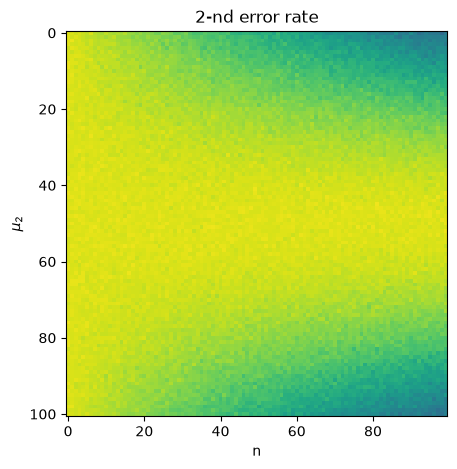

In [13]:
plt.figure(figsize=(5, 5))
plt.imshow(rates, vmin=0, vmax=1)
plt.xlabel('n')
plt.ylabel('$\\mu_2$')
plt.title("2-nd error rate")

In [14]:
mus[60], mus[80], mus[100]

(np.float64(0.19999999999999996),
 np.float64(0.6000000000000001),
 np.float64(1.0))

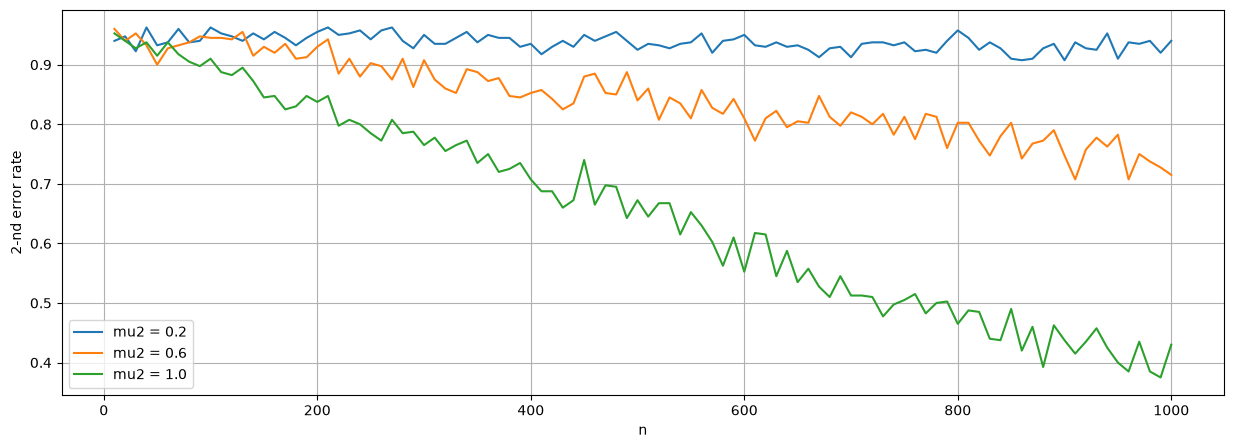

In [15]:
plt.figure(figsize=(15, 5))
plt.plot(range(10, 1001, 10), rates[60], label='mu2 = {:.1f}'.format(mus[60]))
plt.plot(range(10, 1001, 10), rates[80], label='mu2 = {:.1f}'.format(mus[80]))
plt.plot(range(10, 1001, 10), rates[100], label='mu2 = {:.1f}'.format(mus[100]))
plt.xlabel("n")
plt.ylabel("2-nd error rate")
plt.grid()
plt.legend()

Перевірка вручну. При $H_1$:
$$\sqrt{n}\frac{(\hat{\mu}_{1,n}-\hat{\mu}_{2,n})}{\sqrt{\sigma_1^2+\sigma_2^2}} \sim N(d, 1), \quad d = \sqrt{n}\frac{\mu_1-\mu_2}{\sqrt{\sigma_1^2+\sigma_2^2}}$$

Тест приймає $H_0$, якщо $|\zeta_n| \le 1.96$, тому
$$P(\text{похибка II роду}) = \Phi(1.96 - d) - \Phi(-1.96 - d)$$

Наприклад, $\mu_2 = 0.2$, $n = 500$: $d = \sqrt{500}\cdot\frac{-0.2}{14.142} = 22.361 \cdot (-0.01414) = -0.316$

$\Phi(1.96 + 0.316) - \Phi(-1.96 + 0.316) = \Phi(2.276) - \Phi(-1.644) = 0.9886 - 0.0501 = 0.9385$

In [16]:
d = 500 ** 0.5 * (0 - 0.2) / (sigma1 ** 2 + sigma2 ** 2) ** 0.5
d, norm.cdf(kappa - d) - norm.cdf(-kappa - d), rates[60][49]

(-0.31622776601683794, np.float64(0.9384673816911611), np.float64(0.925))

Для наших даних ($n = 1706$, $|\hat{\mu}_{1,n} - \hat{\mu}_{2,n}| \approx 83$):

$d = 41.304 \cdot \frac{83.019}{14.142} = 242.47$, тоді $\Phi(1.96 - 242.47) - \Phi(-1.96 - 242.47) \approx 0$.

In [17]:
d = n ** 0.5 * (x_mean - y_mean) / (sigma1 ** 2 + sigma2 ** 2) ** 0.5
d, norm.cdf(kappa - d) - norm.cdf(-kappa - d)

(-242.46765390805515, np.float64(0.0))

**Висновок про похибку другого роду.** Ймовірність похибки другого роду:
- близька до $1 - a = 0.95$, коли $\mu_2$ близьке до $\mu_1$ (тест майже не відрізняє гіпотези);
- зменшується зі збільшенням $n$ і зі збільшенням $|\mu_1 - \mu_2|$ (на графіку при $\mu_2 = 1$ похибка падає з ≈ 0.95 при малих $n$ до ≈ 0.4 при $n = 1000$).

Моделювання збігається з теоретичною формулою. У наших даних різниця середніх дуже велика, тому ймовірність похибки другого роду практично 0.

# Відповіді (варіант 1)

| | значення |
|---|---|
| $n$ (днів війни) | 1706 |
| $\hat{\mu}_{1,n}$ (ББМ на день) | 15.011 |
| $\hat{\mu}_{2,n}$ (автотехніка на день) | 98.030 |
| $\sigma_1^2 = \sigma_2^2$ | 100 |
| $\zeta_n$ | 242.47 |
| $Q^{N(0, 1)}(1 - a/2)$, $a = 0.05$ | 1.96 |
| критична область | $(1.96, \infty)$ |
| рішення | $H_1$ |
| похибка I роду (моделювання) | ≈ 0.05 |
| похибка II роду для наших даних | ≈ 0 |

# Висновок

$\zeta_n = 242.47 > 1.96$, тому гіпотеза $H_0$ про те, що середні втрати на день ББМ і автомобільної техніки та автоцистерн збігаються, **відхиляється** на рівні значущості $0.05$.

Середні втрати автомобільної техніки (≈ 98 на день) приблизно в 6.5 разів більші за втрати ББМ (≈ 15 на день). Різниця настільки велика, що $\zeta_n$ більше за критичне значення більше ніж у 100 разів, тому висновок не залежить від вибору $a$.

Моделювання показало, що тест коректний: похибка першого роду ≈ 0.05, а похибка другого роду для наших $n$ і різниці середніх практично 0.

Зауваження: дані за кожен день окремо не використовувались — тільки суми, бо статистика $\zeta_n$ залежить лише від середніх. Також ми припустили незалежність вибірок і нормальність (за умовою).